# Turing's model for reaction-diffusion pattern formation

### Introduction


In nature patterns can be found almost everywhere. From trees and their leaves, to other flora and fauna. These regularities, repeating themselves so very often have been the object of mathematicians' interest for centuries.
Alan Turing is not the first example of a mathematician interested in biology and his contribution to the field has been widely recognised. The reason behind this interest is the complexity of living organisms and all the processes regarding their life cycle. Furthermore, many mathematical concepts have been invented just so that naturally occurring phenomena can be explained.
One of the things that have bothered Turing during his life, influencing his research, is the reason why branches form on trees, why animals' fur or skin have certain patterns. What my project strives to achieve is to find the conditions under which this occurs - what properties do the kinetic equations possess that cause the pattern formation. The mathematical model should give a threshold for the formation of certain patterns, while the code will simulate the conditions. The comparison of the results will show whether the math predicts reality.

### Mathematical concept

Consider the presence of two chemicals - activator and inhibitor, causing the pattern formation. Their concentrations are respectively $u$ and $v$. At first, we'll look at the system when there is no diffusion. That said, $u$ and $v$ will change due to reaction, and this change will be presented as a function of these two variables:

$$\frac{du}{dt} = f(u,v)$$
$$\frac{dv}{dt} = g(u,v)$$

where f, g are kinetic functions. The question is what are their properties such that a pattern forms. Theoretically pattern formation occurs when a system goes from a uniform steady state to a complex one, supposedly after introducing diffusion to the system. First we need to find the uniform steady state at $u_{st}$ and $v_{st}$.

$$\begin{cases}
f(u_{st}, v_{st}) = 0 \\
g(u_{st}, v_{st}) = 0
\end{cases}$$

As this system doesn't depend on physical location within space, it is spatially uniform. We assume the steady state (at $u_{st}$ and $v_{st}$) is stable in the absence of diffusion. The stability of a system means that small perturbations of initial conditions decay back to the steady state.

Let $\mathbf{x} = \begin{pmatrix} u - u_{st} \\ v - v_{st} \end{pmatrix}$ be a small perturbation. Linearizing gives

$$\frac{d\mathbf{x}}{dt} = A\,\mathbf{x}, \qquad
A = \begin{pmatrix} f_u & f_v \\ g_u & g_v \end{pmatrix}\Bigg|_{(u_{st},\,v_{st})}$$

where $f_u = \partial f / \partial u$, and so on. The steady state is stable when both eigenvalues of $A$ have negative real part, which for a $2\times 2$ matrix is equivalent to

$$\operatorname{tr} A = f_u + g_v < 0, \qquad \det A = f_u g_v - f_v g_u > 0. \tag1$$

Since $u$ and $v$ are coupled, we describe the state of the system by vector ($u$, $v$) and the perturbation by the vector $x = ((u-u_{st}),(v - v_{st}))$

Along an eigenvector of $A$ with eigenvalue $\lambda = \sigma + i\omega$, the perturbation obeys the scalar equation $\frac{dx}{dt} = \lambda x$, whose solution is

$$x(t) = x(0)\,e^{\lambda t} = x(0)\,e^{\sigma t}\big(\cos(\omega t) + i\sin(\omega t)\big).$$

The oscillating factor has modulus 1, so $|x(t)| = |x(0)|\,e^{\sigma t}$: the perturbation decays if $\sigma < 0$ and grows if $\sigma > 0$. Hence the steady state is stable iff both eigenvalues of $A$ have negative real part.

Since $\lambda_1 + \lambda_2 = \operatorname{tr}A$ and $\lambda_1\lambda_2 = \det A$, this is equivalent to (1)

Now that we have the conditions for stability in the absence of diffusion, what we have to check is if adding diffusion breaks one of these inequalities.

Then diffusion is added to the system and makes the concentrations uniform. For each chemical there is a specific diffusion coefficient that will cause different patterns. I'll call it $D_{u}$ and $D_{v}$ for $u$ and $v$ respectively. Diffusion will affect how the change of concentration changes, therefore it will act on the second derivative with respect to space.


$$\begin{cases}
\frac{du}{dt} = D_u\frac{\partial^2 u}{\partial x^2} + f(u,v)\\
\frac{dv}{dt} = D_v\frac{\partial^2 v}{\partial x^2} + g(u,v)
\end{cases}$$


Diffusion does not change the steady state of the system because a uniform state has zero spatial derivatives, the diffusion terms vanish and the result of the equation is still zero. While some particles are moving and diffusing, the system doesn't change on a macro level. In other words, the steady state stays the same - we're going to be analysing the system of equations with diffusion at $u_{st}$ and $v_{st}$. Linearizing:

$u_l = u - u_{st}$ and $v_l = v - v_{st}$ are small. These are the values at which we're linearizing(fitting a nonlinear equation into a linear one in order to facilitate analysis and calculations; estimation)

$$\begin{cases}
\frac{d u_l}{dt} = D_u\frac{\partial^2 u_l}{\partial x^2} + f_uu_l + f_vv_l\\
\frac{dv_l}{dt} = D_v\frac{\partial^2 v_l}{\partial x^2} + g_uu_l + g_vv_l
\end{cases}\tag2$$

Any perturbation can be expanded in Fourier modes and because of linearity each mode evolves independently. Periodic solutions in x-direction look like $u_l(x,t) = u^*e^{\sigma t}\sin(\alpha x)$ and $v_l(x,t) = v^*e^{\sigma t}\sin(\alpha x)$ after Laplace and Fourier transform. Substituting in (2)

$u^*\sigma e^{\sigma t}\sin(\alpha x) = -\alpha^2 D_uu^*e^{\sigma t}sin(\alpha x) + f_uu^*e^{\sigma t}\sin(\alpha x) + f_vv^*e^{\sigma t}\sin(\alpha x) \Leftrightarrow u^*\sigma = -\alpha^2 D_uu^* + f_uu^* + f_vv^*$

$$\begin{cases}
u^*\sigma = -\alpha^2 D_uu^* + f_uu^* + f_vv^*\\
v^*\sigma = -\alpha^2 D_vv^* + g_uu^* + g_vv^*
\end{cases}\tag3$$

In this system of equations $\sigma$ is the eigenvalue. Writing the system in a vectorial form will make it clear why:

$$\sigma \begin{pmatrix}
u^*\\
v^*
\end{pmatrix} = \begin{bmatrix}
f_u-\alpha^2D_u & f_v \\
g_u & g_v-\alpha^2D_v
\end{bmatrix}\begin{pmatrix}
u^*\\
v^*
\end{pmatrix}$$

As already said, for stability to be present the real part of the eigenvalue needs to be negative - both the trace must be negative and the determinant positive.

$$\begin{cases}
f_u + g_v -\alpha^2(D_u+D_v)<0\\
f_ug_v -f_vg_u - \alpha^2(f_uD_v+g_vD_u)+\alpha^4D_uD_v>0
\end{cases}\tag4$$

From (1) we already know that $f_u+g_v<0$ and $f_ug_v-f_vg_u>0$. The sum of the two positive coefficients will always be positive, therefore $\alpha^2(D_u+D_v)>0$, meaning that the trace is always negative. For instability, we want either of the the fore-mentioned conditions to not be satisfied. For the determinant to be less than zero, $f_uD_v+g_vD_u>0$, although it isn't guaranteed. Given that $f_u+g_v<0$, in order for the previous equation to be positive, $f_u$ and $g_v$ must have opposite signs. Let $f_u>0$ and $g_v<0$. Remember that $\frac{du}{dt}=f(u,v)$. When the partial derivative of $f$ with respect to $u$ is positive, that means that the concentration of $u$ is increasing. Therefore, with the rising concentration of $u$ the reaction rate also increasing. By following the same logic, we can deduct that as the concentration of $v$ increases, the reaction rate decreases. In chemical terms, $u$ is an activator, whereas $v$ is an inhibitor.

A necessary condition is that $|g_v|>|f_u|$ and $D_vf_u>-D_ug_v \Rightarrow \frac{D_v}{D_u}>-\frac{g_v}{f_u}>1$. Transitioning from mathematical formulas, this means that the inhibitor diffuses faster than the activator. In order to get a clearer insight on the instability condition, we'll also have to analyse the determinant of Jacobian matrix with diffusion.

$\alpha^4D_uD_v - \alpha^2(f_uD_v+g_vD_u)+f_ug_v-f_vg_u>0 \Rightarrow D_eq>0 \Leftrightarrow (f_uD_v + g_vD_u)^2 -4D_uD_v(f_ug_v - f_vg_u)>0$

$\det A_\alpha$ is a quadratic in $q=\alpha^2$:
$$h(q) = D_uD_v\,q^2 - b\,q + \det A, \qquad h(0)=\det A>0.$$
$\det A_\alpha<0$ means the mode $\alpha$ grows, so we need $h(q)<0$ for some $q>0$. Since $h$ opens upward and starts positive, this happens iff its vertex $q_c = b/(2D_uD_v)$ is positive and its minimum value is negative:

$$b>0, \qquad b^2>4D_uD_v\det A. \tag{5}$$

Together with (1), the conditions for a Turing instability are
$$f_u+g_v<0,\quad f_ug_v-f_vg_u>0,\quad D_vf_u+D_ug_v>0,\quad (D_vf_u+D_ug_v)^2>4D_uD_v(f_ug_v-f_vg_u).$$

The unstable modes are those with $q$ between the two roots $q_\pm = \frac{b\pm\sqrt{b^2-4D_uD_v\det A}}{2D_uD_v}$ of $h$. At the threshold, $b^2=4D_uD_v\det A$, a single critical wavenumber appears, $\alpha_c^2=\sqrt{\det A/(D_uD_v)}$, and the pattern has wavelength about $2\pi/\alpha_c$. These two predictions, the threshold in $D_v/D_u$ and the wavelength, are what we will compare with the simulation.

### Code simulation

In [13]:
%matplotlib inline
import numpy as np;
import matplotlib.pyplot as plt;

Since the instability conditions I discovered are not sufficient for me to write code, simulating pattern formation, I'll use the Schnakenberg model.

$$\begin{cases}
\frac{\partial u}{\partial t} = D_u \frac{\partial^2u}{\partial x^2}+a-u+u^2v\\
\frac{\partial v}{\partial t} = D_v\frac{\partial^v}{\partial x^2} + b - u^2v
\end{cases}$$

According to the model $f(u,v) = a-u+u^2v$ and $g(u,v)=b-u^2v$. At the steady state they are both zero and by applying the analysis we get the following conditions:

$$u_{st} = a+b, v_{st} = \frac{b}{(a+b)^2}$$
$$f_u=\frac{b-a}{a+b}, f_v = (a+b)^2$$
$$g_u = \frac{-2b}{a+b}, g_v = -(a+b)^2$$
To satisfy condition (1): $f_ug_v-f_vg_u>0$ and $f_u+g_v<0$, we must have $(a+b)^3>b-a$; from the sign analysis: $b>a$

In [14]:
n = 100
dx = 1.00
a = 0.1
b=0.9
Du = 1.00
Dv = 10.00
u_st = a+b
v_st = b/(a+b)**2
def reaction(U,V):
    f=a-U+U**2*V
    g=b-U**2*V
    return f,g
def jacobian_steady_state(a,b):
    """computing the jacobian matrix - f_u, f_v, g_u, g_v"""
    s = a+b
    return (b-a)/s, s**2, (-2*b)/s, -s**2
def turing_analysis(a,b,U,V):
    """"checking conditions and evaluating wavenumbers"""
    fu, fv, gu, gv = jacobian_steady_state(a,b)
    tr, det = fu+gv, fu*gv-fv*gu
    b_cond = fu*Dv+gv*Du
    discr = b_cond**2 -4*Du*Dv*det
    turing = (tr<0) and (det>0) and (b_cond>0) and (discr>0)
    out = {"stable_without_diffusion": (tr < 0) and (det > 0), "turing": turing}
    if turing:
        q_lo = (b_cond-np.sqrt(discr))/2*Du*Dv
        q_hi = (b_cond+np.sqrt(discr))/2*Du*Dv
        q_max = b_cond/2*Du*Dv
        out.update(alpha_lo=np.sqrt(q_lo), alpha_hi=np.sqrt(q_hi),
                   alpha_max=np.sqrt(q_max), wavelength=2 * np.pi / np.sqrt(q_max))
        return out
def critical_dv(a, b, Du):
    fu, fv, gu, gv = jacobian_steady_state(a,b)
    det = fu*gv-fv*gu
    # (fu Dv + gv Du)^2 - 4 Du Dv det = 0
    roots = np.roots([fu**2, 2 * fu * gv * Du - 4 * Du * det, (gv * Du)**2])
    valid = [r.real for r in roots if abs(r.imag) < 1e-12 and fu * r.real + gv * Du > 0]
    return max(valid)
crit_Dv = critical_dv(a, b, Du)
print(f"Steady state: u_st = {u_st:.3f}, v_st = {v_st:.3f}")
print(f"Theoretical threshold: D_v / D_u > {crit_Dv / Du:.3f}")
print(turing_analysis(a, b, Du, 10.0))

Steady state: u_st = 1.000, v_st = 0.900
Theoretical threshold: D_v / D_u > 8.568
{'stable_without_diffusion': True, 'turing': True, 'alpha_lo': np.float64(4.47213595499958), 'alpha_hi': np.float64(7.0710678118654755), 'alpha_max': np.float64(5.916079783099616), 'wavelength': np.float64(1.0620521591221057)}


In [15]:

def laplacian1D(Z, dx=1.00):
    Zp = np.pad(Z, 1, mode="edge")
    return (Zp[:-2] + Zp[2:] - 2 * Z) / dx**2
def laplacian2D(Z, dx=1.00):
    Zp = np.pad(Z, 1, mode="edge")
    return (Zp[:-2, 1:-1] + Zp[2:, 1:-1] + Zp[1:-1, :-2] + Zp[1:-1, 2:] - 4 * Z) / dx**2

In [16]:
"""advancing u and v one step at a time"""
def step(U, V, Du, Dv, dt, laplacian, dx =1.00):
    f, g = reaction(U, V)
    U_new = U + dt*(Du*laplacian(U, dx)+f)
    V_new = V + dt*(Dv*laplacian(V, dx)+g)
    return U_new, V_new
def safeDt(Du, Dv, dx, dim, safety=0.4):
    return safety * dx**2 / (2 * dim * max(Du, Dv))

The check for a safe $dt$ is necessary because the explicit Euler is only stable when $dt<\frac{dx^2}{2dim D_{max}}$. The function only uses 40% of that limit

In [17]:
def initial_state(shape, noise=0.01, seed = 42 ):
    rng = np.random.default_rng(seed)
    U = u_st * (1 + noise * rng.standard_normal(shape))
    V = v_st * (1 + noise * rng.standard_normal(shape))
    return U, V
"""Using noise to simulate randomness and small perturbations"""
def simulate(shape, Du, Dv, T, dx=1.0, seed=42):
    dim = len(shape)
    laplacian = laplacian1D if dim == 1 else laplacian2D
    dt = safeDt(Du, Dv, dx, dim, safety=0.4)
    U, V = initial_state(shape, seed=seed)
    for _ in range(int(T / dt)):
        U, V = step(U, V, Du, Dv, dt, laplacian, dx)
    return U, V

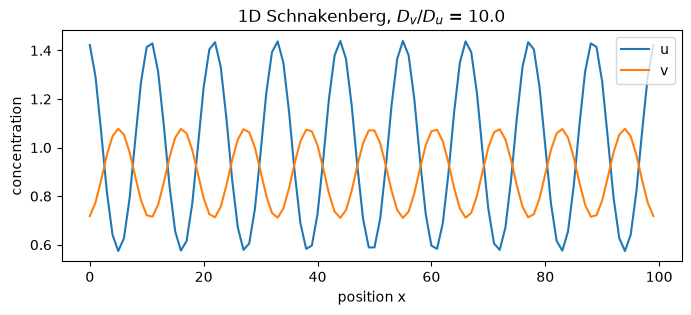

In [18]:
"""1-`D simulation"""
N1 = 100
Dv = 10.0
U1, V1 = simulate((N1,),Du, Dv, T=5000)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(U1, label="u")
ax.plot(V1, label="v")
ax.set_xlabel("position x")
ax.set_ylabel("concentration")
ax.set_title(f"1D Schnakenberg, $D_v/D_u$ = {Dv / Du:.1f}")
ax.legend()
plt.show()


In [19]:
def dominant_wavelength(V, dx=1.0):
    Vc = V - V.mean()
    mirrored = np.concatenate([Vc, Vc[::-1]])
    spectrum = np.abs(np.fft.rfft(mirrored))
    n = np.argmax(spectrum[1:]) + 1
    L = len(V) * dx
    alpha = n * np.pi / L
    return 2 * np.pi / alpha
theory = turing_analysis(a, b, Du, Dv)
print(f"Measured wavelength:  {dominant_wavelength(V1):.1f}")
print(f"Predicted (linear theory): {theory['wavelength']:.1f}")
print("Only wavenumbers alpha = n*pi/L are allowed on a finite domain, so the measured")
print("value is the allowed mode closest to the predicted one.")

Measured wavelength:  11.1
Predicted (linear theory): 1.1
Only wavenumbers alpha = n*pi/L are allowed on a finite domain, so the measured
value is the allowed mode closest to the predicted one.


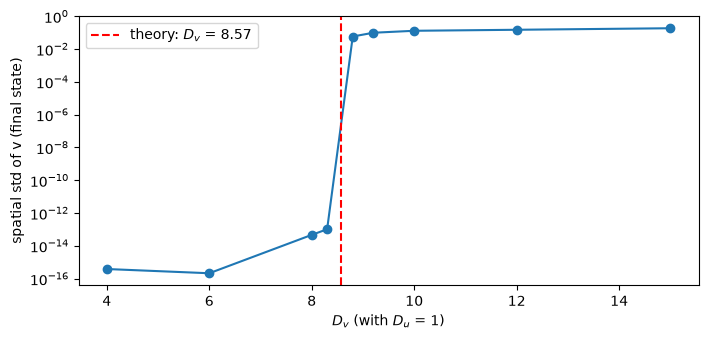

D_v =   4.0  pattern in simulation: False  theory predicts: False
D_v =   6.0  pattern in simulation: False  theory predicts: False
D_v =   8.0  pattern in simulation: False  theory predicts: False
D_v =   8.3  pattern in simulation: False  theory predicts: False
D_v =   8.8  pattern in simulation: True   theory predicts: True 
D_v =   9.2  pattern in simulation: True   theory predicts: True 
D_v =  10.0  pattern in simulation: True   theory predicts: True 
D_v =  12.0  pattern in simulation: True   theory predicts: True 
D_v =  15.0  pattern in simulation: True   theory predicts: True 


In [20]:
Dv_values = [4, 6, 8, 8.3, 8.8, 9.2, 10, 12, 15]
amplitudes = []
for Dv_i in Dv_values:
    _, V_i = simulate((N1,), Du, Dv_i, T=5000)
    amplitudes.append(V_i.std())
amplitudes = np.array(amplitudes)
pattern = amplitudes > 1e-3
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(Dv_values, np.maximum(amplitudes, 1e-16), "o-")
ax.axvline(crit_Dv, color="red", ls="--", label=f"theory: $D_v$ = {crit_Dv:.2f}")
ax.set_xlabel("$D_v$ (with $D_u$ = 1)")
ax.set_ylabel("spatial std of v (final state)")
ax.legend()
plt.show()
for Dv_i, amp, p in zip(Dv_values, amplitudes, pattern):
    theory_says = Dv_i > crit_Dv
    print(f"D_v = {Dv_i:5.1f}  pattern in simulation: {p!s:5}  theory predicts: {theory_says!s:5}")